# Model Performance Comparison – Paddy Leaf Nutrient Deficiency Classification

This notebook provides a **comprehensive, side-by-side comparison** of six deep-learning architectures trained on the paddy leaf nutrient-deficiency dataset (`dataset/images/`). The three target classes are:

| Label | Deficiency |
|-------|------------|
| 0 | Nitrogen |
| 1 | Phosphorous |
| 2 | Potassium |

## Models Compared
1. **ResNet-50** – Deep residual network (transfer learning from ImageNet)
2. **MobileNet** – Lightweight depthwise-separable architecture (transfer learning)
3. **EfficientNet** – Compound-scaled architecture (transfer learning)
4. **Large CNN** – A standard deep CNN built from scratch
5. **TinyCNN** – A minimal, lightweight CNN for baseline comparison
6. **CAR-Capsule** – Capsule network with Class-Aware Routing

## Data Preprocessing Pipeline (per proposal)
The preprocessing follows the multi-stage pipeline described in the research proposal:
1. **Color Enhancement** – CLAHE contrast boosting in LAB color space
2. **Data Augmentation** – Random rotation, flips, and zoom
3. **Noise Removal** – Gaussian blur denoising
4. **Normalization** – Min-max normalization to [0, 1]; ResNet-50 applies ImageNet channel normalization before inference

## Frameworks
All models use **TensorFlow / Keras** for training and inference.

> **How to run:** Execute the cells sequentially from the project root. Make sure you have installed the dependencies listed in the notebook environment, including TensorFlow.


---
## 1. Imports and Configuration

In [ ]:
import os
import random
import time
import warnings
import math

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import (
    ResNet50,
    MobileNetV2,
    EfficientNetB0,
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")

# ── Configuration ──
DATA_DIR = Path("../dataset/images")
OUTPUT_DIR = Path("outputs/model_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["nitrogen", "phosphorous", "potassium"]
NUM_CLASSES = len(CLASSES)
IMAGE_SIZE = 224          # Standard input size for pretrained models
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-3
SEED = 42
USE_PRETRAINED = True
FREEZE_BACKBONE = False

# Reproducibility and GPU memory configuration.
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf_gpus = tf.config.list_physical_devices("GPU")
for gpu in tf_gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
DEVICE = "GPU:0" if tf_gpus else "CPU:0"
RESNET50_COMPUTE_POLICY = "mixed_float16" if tf_gpus else "float32"

print(f"TensorFlow version : {tf.__version__}")
print(f"Training device    : {DEVICE}")
print(f"ResNet50 policy    : {RESNET50_COMPUTE_POLICY}")
print(f"Image size         : {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Batch size         : {BATCH_SIZE}")
print(f"Epochs             : {EPOCHS}")
print(f"ResNet50 LR        : {LEARNING_RATE}")
print(f"Freeze backbone    : {FREEZE_BACKBONE}")


---
## 2. Load and Explore the Dataset

We scan the three class folders and collect every valid image path alongside its integer label.

In [92]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = []
image_labels = []

for label, class_name in enumerate(CLASSES):
    class_dir = DATA_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Missing class folder: {class_dir.resolve()}")

    files = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )
    image_paths.extend(files)
    image_labels.extend([label] * len(files))
    print(f"  {class_name:>15s} : {len(files)} images")

image_paths = np.array(image_paths, dtype=object)
image_labels = np.array(image_labels, dtype=np.int64)

print(f"\nTotal images: {len(image_paths)}")

         nitrogen : 440 images
      phosphorous : 333 images
        potassium : 383 images

Total images: 1156


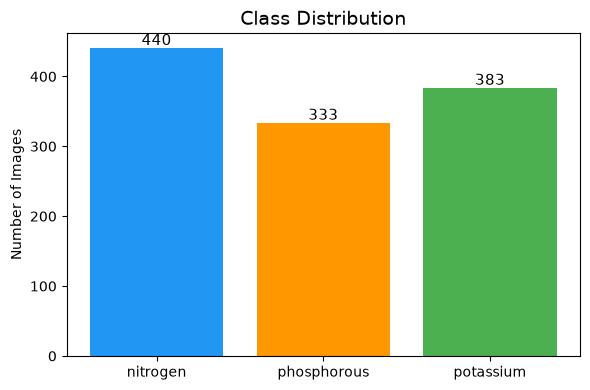

In [93]:
# Visualize class distribution
counts = [int((image_labels == i).sum()) for i in range(NUM_CLASSES)]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASSES, counts, color=["#2196F3", "#FF9800", "#4CAF50"])
ax.set_title("Class Distribution", fontsize=14)
ax.set_ylabel("Number of Images")

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha="center", fontsize=11,
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150)
plt.show()

---
## 3. Stratified Train / Validation / Test Split

We use a **70 / 15 / 15** stratified split so that every model is trained and evaluated on the same data.

In [94]:
# First split: 70% train, 30% remainder
train_idx, rem_idx = train_test_split(
    np.arange(len(image_labels)),
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels,
)

# Second split: 50/50 of the remainder → 15% val, 15% test
val_idx, test_idx = train_test_split(
    rem_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=image_labels[rem_idx],
)

print(f"Train      : {len(train_idx)} samples")
print(f"Validation : {len(val_idx)} samples")
print(f"Test       : {len(test_idx)} samples")

Train      : 809 samples
Validation : 173 samples
Test       : 174 samples


---
## 4. Data Preprocessing Pipeline

Following the **multi-stage image preprocessing pipeline** described in the research proposal, each image goes through:

| Step | Technique | Purpose |
|------|-----------|---------|
| 1 | CLAHE on L-channel (LAB) | **Color enhancement** – boost local contrast |
| 2 | Random rotation (±30°) | **Data augmentation** – improve generalization |
| 3 | Gaussian blur (5×5 kernel) | **Noise removal** – suppress high-frequency noise |
| 4 | Min-max scaling to [0, 1] | **Normalization** – standardize pixel range |

In [95]:
def preprocess_image(path, target_size=IMAGE_SIZE, augment=False):
    """
    Load and preprocess a single image following the proposal pipeline:
      1. Color enhancement  (CLAHE on the L-channel in LAB space)
      2. Noise removal      (Gaussian blur)
      3. Data augmentation   (random rotation – training only)
      4. Normalization       (min-max to [0, 1])
    """
    # Read image in BGR
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"Cannot read image: {path}")

    # Resize to target dimensions
    img = cv2.resize(img, (target_size, target_size))

    # --- Step 1: Color Enhancement (CLAHE) ---
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_channel = clahe.apply(l_channel)
    lab = cv2.merge([l_channel, a_channel, b_channel])
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    # --- Step 2: Noise Removal (Gaussian Blur) ---
    img = cv2.GaussianBlur(img, (5, 5), 0)

    # --- Step 3: Data Augmentation (random rotation – train only) ---
    if augment:
        angle = random.uniform(-30, 30)
        center = (target_size // 2, target_size // 2)
        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(
            img, matrix, (target_size, target_size),
            borderMode=cv2.BORDER_REFLECT_101,
        )

    # Convert BGR → RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- Step 4: Normalization (min-max to [0, 1]) ---
    img = img.astype(np.float32) / 255.0

    return img

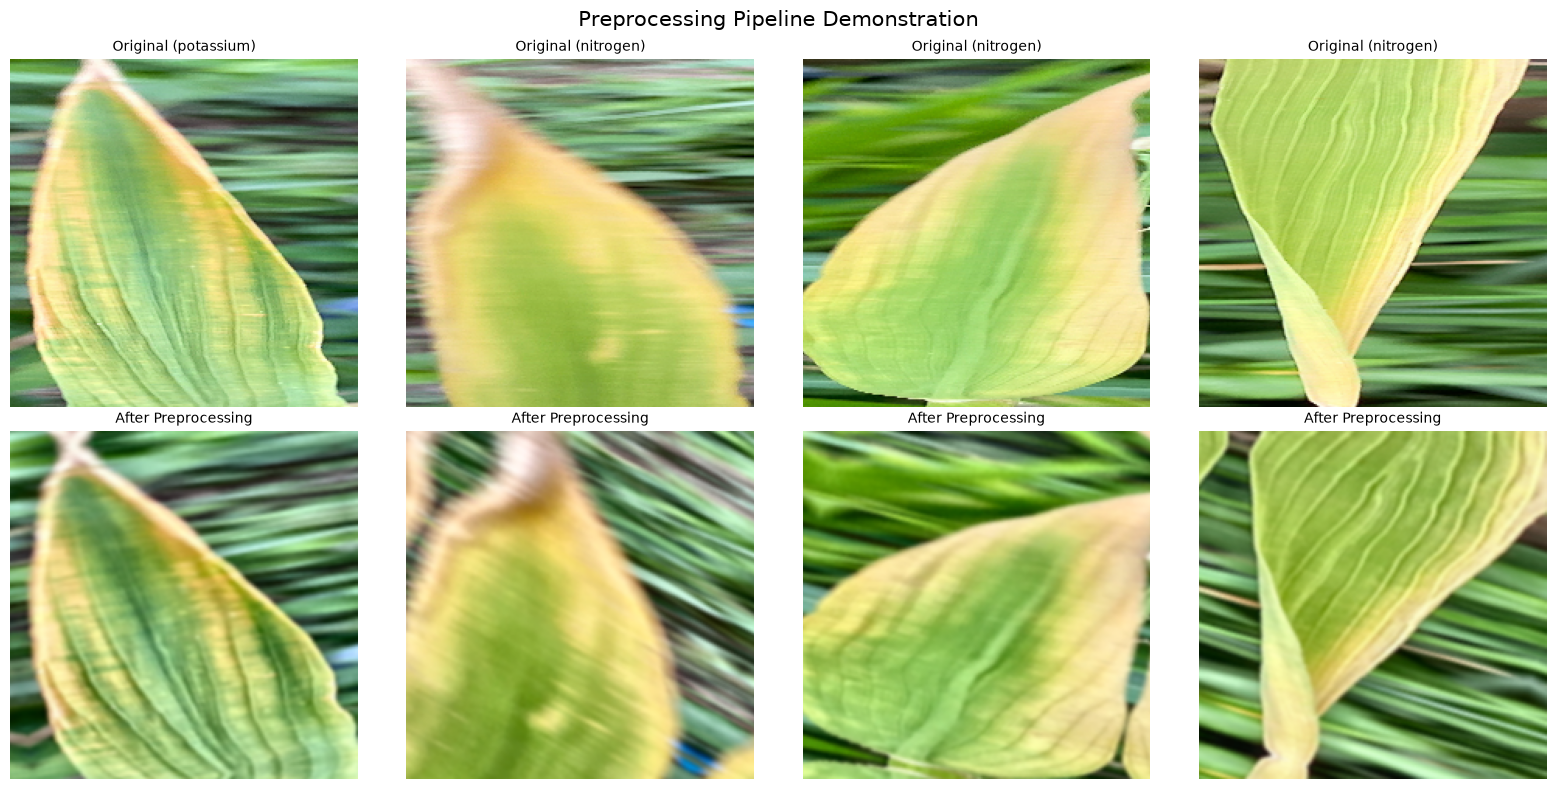

In [96]:
# Show preprocessing on a few sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Preprocessing Pipeline Demonstration", fontsize=15)

sample_idx = np.random.choice(len(image_paths), 4, replace=False)

for col, idx in enumerate(sample_idx):
    path = image_paths[idx]
    label = CLASSES[image_labels[idx]]

    # Original
    original = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    original = cv2.resize(original, (IMAGE_SIZE, IMAGE_SIZE))
    axes[0, col].imshow(original)
    axes[0, col].set_title(f"Original ({label})", fontsize=10)
    axes[0, col].axis("off")

    # Preprocessed
    processed = preprocess_image(path, augment=True)
    axes[1, col].imshow(processed)
    axes[1, col].set_title("After Preprocessing", fontsize=10)
    axes[1, col].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "preprocessing_demo.png", dpi=150)
plt.show()

---
## 5. Build TensorFlow Data Pipelines

We preprocess **all** images up-front and store them in NumPy arrays so every model trains on the exact same data. The `tf.data.Dataset` API handles batching and shuffling.

In [97]:
def load_split(indices, augment=False):
    """Load and preprocess all images for a given split."""
    images = []
    labels = []
    for i in indices:
        img = preprocess_image(image_paths[i], augment=augment)
        images.append(img)
        labels.append(image_labels[i])
    return np.array(images), np.array(labels)


print("Loading training images...")
X_train, y_train = load_split(train_idx, augment=True)

print("Loading validation images...")
X_val, y_val = load_split(val_idx, augment=False)

print("Loading test images...")
X_test, y_test = load_split(test_idx, augment=False)

print(f"\nShapes  →  train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")

Loading training images...
Loading validation images...
Loading test images...

Shapes  →  train: (809, 224, 224, 3), val: (173, 224, 224, 3), test: (174, 224, 224, 3)


In [98]:
def make_dataset(X, y, shuffle=False):
    """Wrap numpy arrays into a tf.data.Dataset."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds   = make_dataset(X_val, y_val)
test_ds  = make_dataset(X_test, y_test)

print("Datasets ready.")

Datasets ready.


---
## 6. Define All Six Models

Each builder returns a compiled `tf.keras.Model` ready for `.fit()`. ResNet-50 uses ImageNet weights, the requested trainable/frozen backbone option, AdamW, and an epoch-wise cosine learning-rate schedule.


### 6.1  ResNet-50 (Transfer Learning)

In [ ]:
def build_resnet50():
    previous_policy = keras.mixed_precision.global_policy()
    keras.mixed_precision.set_global_policy(RESNET50_COMPUTE_POLICY)
    try:
        weights = "imagenet" if USE_PRETRAINED else None
        try:
            backbone = ResNet50(
                weights=weights,
                include_top=False,
                input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
            )
        except Exception as exc:
            if not USE_PRETRAINED:
                raise
            print(f"Could not load pretrained weights ({exc}); initializing randomly instead.")
            backbone = ResNet50(
                weights=None,
                include_top=False,
                input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
            )

        backbone.trainable = not FREEZE_BACKBONE

        # Apply RGB ImageNet normalization to [0, 1] input images.
        inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
        x = layers.Rescaling(255.0)(inputs)
        x = layers.Normalization(
            mean=[123.675, 116.28, 103.53],
            variance=[58.395 ** 2, 57.12 ** 2, 57.375 ** 2],
        )(x)
        x = backbone(x)
        x = layers.GlobalAveragePooling2D()(x)
        logits = layers.Dense(NUM_CLASSES, dtype="float32")(x)
        model = keras.Model(inputs, logits, name="ResNet50")
    finally:
        keras.mixed_precision.set_global_policy(previous_policy)

    resnet50_lr_schedule = keras.callbacks.LearningRateScheduler(
        lambda epoch, _: LEARNING_RATE
        * 0.5
        * (1.0 + math.cos(math.pi * epoch / EPOCHS)),
        verbose=0,
    )
    optimizer = keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=1e-4,
    )
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
        auto_scale_loss=RESNET50_COMPUTE_POLICY == "mixed_float16",
    )
    model.resnet50_callbacks = [resnet50_lr_schedule]
    return model


print("ResNet-50 builder ready.")


### 6.2  MobileNet (Transfer Learning)

In [100]:
def build_mobilenet():
    """
    MobileNetV2 with ImageNet weights.
    Designed for mobile/edge deployment – very lightweight.
    """
    base = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    )
    base.trainable = False

    model = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="MobileNet")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("MobileNet builder ready.")

MobileNet builder ready.


### 6.3  EfficientNet (Transfer Learning)

In [101]:
def build_efficientnet():
    """
    EfficientNetB0 with ImageNet weights.
    Uses compound scaling for balanced depth/width/resolution.
    """
    base = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    )
    base.trainable = False

    model = keras.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="EfficientNet")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("EfficientNet builder ready.")

EfficientNet builder ready.


### 6.4  Large CNN (Standard Deep CNN)

In [102]:
def build_large_cnn():
    """
    A standard deep CNN built from scratch.
    Four convolutional blocks with increasing filter depth,
    batch normalization, and dropout for regularization.
    """
    model = keras.Sequential(name="LargeCNN")

    # Block 1
    model.add(layers.Conv2D(32, (3, 3), activation="relu",
                            padding="same",
                            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(32, (3, 3), activation="relu", padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))

    # Block 2
    model.add(layers.Conv2D(64, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, (3, 3), activation="relu", padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))

    # Block 3
    model.add(layers.Conv2D(128, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, (3, 3), activation="relu", padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))

    # Block 4
    model.add(layers.Conv2D(256, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(256, (3, 3), activation="relu", padding="same"))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.25))

    # Classification head
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("Large CNN builder ready.")

Large CNN builder ready.


### 6.5  TinyCNN (Minimal Baseline)

In [103]:
def build_tiny_cnn():
    """
    A minimal two-block CNN for a lightweight baseline.
    Useful to gauge the difficulty of the task.
    """
    model = keras.Sequential([
        layers.Conv2D(16, (3, 3), activation="relu",
                      input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="TinyCNN")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("TinyCNN builder ready.")

TinyCNN builder ready.


### 6.6  CAR-Capsule (Capsule Network with Class-Aware Routing)

Capsule networks encode **part-whole relationships** via vector-valued capsules and iterative routing. This is beneficial for detecting nutrient-deficiency patterns that differ in pose and spatial arrangement.

The architecture consists of:
1. A convolutional feature extractor
2. A **PrimaryCaps** layer that reshapes features into capsule vectors
3. A **ClassCapsule** layer with dynamic routing (squash activation)

In [104]:
# ── Capsule helper functions ──

def squash(vectors, axis=-1):
    """Squash activation: non-linear normalization for capsule vectors."""
    sq_norm = tf.reduce_sum(tf.square(vectors), axis=axis, keepdims=True)
    scale = sq_norm / (1.0 + sq_norm) / tf.sqrt(sq_norm + 1e-8)
    return scale * vectors


class PrimaryCaps(layers.Layer):
    """Convert conv features to capsule vectors."""

    def __init__(self, num_capsules, capsule_dim, kernel_size, strides, **kw):
        super().__init__(**kw)
        self.num_capsules = num_capsules
        self.capsule_dim = capsule_dim
        self.conv = layers.Conv2D(
            num_capsules * capsule_dim,
            kernel_size, strides=strides,
            padding="valid", activation="relu",
        )

    def call(self, x):
        out = self.conv(x)
        batch = tf.shape(out)[0]
        # Reshape: (batch, H*W*num_capsules, capsule_dim)
        out = tf.reshape(out, [batch, -1, self.capsule_dim])
        return squash(out)


class ClassCapsule(layers.Layer):
    """Class-aware routing capsule layer."""

    def __init__(self, num_classes, capsule_dim, routing_iters=3, **kw):
        super().__init__(**kw)
        self.num_classes = num_classes
        self.capsule_dim = capsule_dim
        self.routing_iters = routing_iters

    def build(self, input_shape):
        # input_shape = (batch, num_input_caps, input_dim)
        self.num_input_caps = input_shape[1]
        self.input_dim = input_shape[2]

        # Weight matrix W: (num_input_caps, num_classes, input_dim, capsule_dim)
        self.W = self.add_weight(
            name="routing_weights",
            shape=(self.num_input_caps, self.num_classes,
                   self.input_dim, self.capsule_dim),
            initializer="glorot_uniform",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        batch = tf.shape(inputs)[0]

        # Expand dims for matmul: (batch, num_input, 1, 1, input_dim)
        u = tf.expand_dims(tf.expand_dims(inputs, 2), 2)
        # Tile W: broadcast over batch
        u_hat = tf.reduce_sum(u * self.W, axis=-2)  # → (batch, num_input, num_classes, cap_dim)

        # Dynamic routing
        b = tf.zeros([batch, self.num_input_caps, self.num_classes, 1])
        for _ in range(self.routing_iters):
            c = tf.nn.softmax(b, axis=2)          # coupling coefficients
            s = tf.reduce_sum(c * u_hat, axis=1, keepdims=True)  # weighted sum
            v = squash(s, axis=-1)                 # class capsules
            agreement = tf.reduce_sum(u_hat * v, axis=-1, keepdims=True)
            b = b + agreement

        # Remove the keepdims=True axis → (batch, num_classes, capsule_dim)
        v = tf.squeeze(v, axis=1)
        return v


print("Capsule layers defined.")

Capsule layers defined.


In [105]:
def build_car_capsule():
    """
    CAR-Capsule network:
      Conv feature extractor → PrimaryCaps → ClassCapsule → norm → softmax.
    """
    inp = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Feature extractor
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(256, (9, 9), activation="relu", strides=2, padding="valid")(x)
    x = layers.BatchNormalization()(x)

    # Primary capsules
    x = PrimaryCaps(
        num_capsules=8, capsule_dim=16,
        kernel_size=9, strides=2,
    )(x)

    # Class capsules (one per deficiency class)
    x = ClassCapsule(
        num_classes=NUM_CLASSES,
        capsule_dim=16,
        routing_iters=3,
    )(x)

    # The length (norm) of each class capsule = probability of that class
    out = layers.Lambda(
        lambda v: tf.sqrt(tf.reduce_sum(tf.square(v), axis=-1) + 1e-8)
    )(x)

    model = Model(inputs=inp, outputs=out, name="CAR_Capsule")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


print("CAR-Capsule builder ready.")

CAR-Capsule builder ready.


---
## 7. Train All Models

All models use the same data splits, batch size, and epoch count. ResNet-50 uses TensorFlow mixed precision with automatic loss scaling on GPU, AdamW (weight decay `1e-4`), and cosine annealing over 20 epochs; the other models retain their existing TensorFlow/Keras training settings.


In [ ]:
# Registry of model builders
MODEL_BUILDERS = {
    # "CAR-Capsule":   build_car_capsule,
    "ResNet-50":     build_resnet50,
    "MobileNet":     build_mobilenet,
    "EfficientNet":  build_efficientnet,
    "Large CNN":     build_large_cnn,
    "TinyCNN":       build_tiny_cnn,
}

# Storage for results
results = {}  # {name: {history, model, time, params, ...}}

# Common callbacks for the TensorFlow/Keras models.
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=0),
]

for name, builder in MODEL_BUILDERS.items():
    print(f"\n{'='*60}")
    print(f"  Training: {name}")
    print(f"{'='*60}")

    model = builder()
    total_params = model.count_params()
    trainable_params = sum(
        int(np.prod(weight.shape)) for weight in model.trainable_weights
    )
    print(f"  Total params     : {total_params:,}")
    print(f"  Trainable params : {trainable_params:,}")

    model_callbacks = (
        model.resnet50_callbacks if name == "ResNet-50" else callbacks
    )
    start = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=model_callbacks,
        verbose=1,
    )
    elapsed = time.time() - start

    results[name] = {
        "model": model,
        "history": history.history,
        "time": elapsed,
        "total_params": total_params,
        "trainable_params": trainable_params,
    }
    print(f"  Training time: {elapsed:.1f}s")

print("\n✅ All models trained.")


---
## 8. Evaluate All Models on the Test Set

We run inference on the held-out test split and collect predictions for every model.

In [ ]:
for name, res in results.items():
    model = res["model"]
    logits = model.predict(test_ds, verbose=0)

    if name == "ResNet-50":
        y_prob = tf.nn.softmax(logits, axis=1).numpy()
        test_loss = float(
            keras.losses.sparse_categorical_crossentropy(
                y_test,
                logits,
                from_logits=True,
            ).numpy().mean()
        )
    else:
        y_prob = logits
        test_loss, _ = model.evaluate(test_ds, verbose=0)

    y_pred = np.argmax(y_prob, axis=1)
    test_acc = float(np.mean(y_pred == y_test))
    res["y_prob"] = y_prob
    res["y_pred"] = y_pred
    res["test_loss"] = test_loss
    res["test_accuracy"] = test_acc

    print(f"{name:>15s}  →  Test Accuracy: {test_acc:.4f}  |  Test Loss: {test_loss:.4f}")

print("\nEvaluation complete.")


---
## 9. Summary Comparison Table

In [ ]:
rows = []
for name, res in results.items():
    report = classification_report(
        y_test, res["y_pred"],
        labels=range(NUM_CLASSES),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0,
    )
    rows.append({
        "Model": name,
        "Test Accuracy": f"{res['test_accuracy']:.4f}",
        "Test Loss": f"{res['test_loss']:.4f}",
        "Precision (macro)": f"{report['macro avg']['precision']:.4f}",
        "Recall (macro)": f"{report['macro avg']['recall']:.4f}",
        "F1-Score (macro)": f"{report['macro avg']['f1-score']:.4f}",
        "Total Params": f"{res['total_params']:,}",
        "Trainable Params": f"{res['trainable_params']:,}",
        "Training Time (s)": f"{res['time']:.1f}",
    })

summary_df = pd.DataFrame(rows)
summary_df = summary_df.set_index("Model")
display(summary_df)

# Save to CSV
summary_df.to_csv(OUTPUT_DIR / "model_comparison_summary.csv")
print(f"\nSaved to {OUTPUT_DIR / 'model_comparison_summary.csv'}")

---
## 10. Visualization: Test Accuracy & Loss Comparison

In [ ]:
names = list(results.keys())
accs = [results[n]["test_accuracy"] for n in names]
losses = [results[n]["test_loss"] for n in names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy bars
colors = ["#2196F3", "#FF9800", "#4CAF50", "#9C27B0", "#F44336", "#00BCD4"]
bars1 = axes[0].barh(names, accs, color=colors)
axes[0].set_xlabel("Test Accuracy")
axes[0].set_title("Test Accuracy by Model", fontsize=13)
axes[0].set_xlim(0, 1.05)
for bar, acc in zip(bars1, accs):
    axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{acc:.3f}", va="center", fontsize=10)

# Loss bars
bars2 = axes[1].barh(names, losses, color=colors)
axes[1].set_xlabel("Test Loss")
axes[1].set_title("Test Loss by Model", fontsize=13)
for bar, loss in zip(bars2, losses):
    axes[1].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{loss:.3f}", va="center", fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_loss_comparison.png", dpi=150)
plt.show()

---
## 11. Training History Curves

Loss and accuracy over epochs for every model, plotted side by side.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Training & Validation Curves", fontsize=16, y=1.02)

for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx // 3, idx % 3]
    hist = res["history"]

    epochs_range = range(1, len(hist["loss"]) + 1)

    ax.plot(epochs_range, hist["loss"], "b-", label="Train Loss")
    ax.plot(epochs_range, hist["val_loss"], "r--", label="Val Loss")

    # Accuracy on secondary axis
    ax2 = ax.twinx()
    ax2.plot(epochs_range, hist["accuracy"], "g-", alpha=0.7, label="Train Acc")
    ax2.plot(epochs_range, hist["val_accuracy"], "m--", alpha=0.7, label="Val Acc")
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Accuracy")

    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")

    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

---
## 12. Confusion Matrices

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("Confusion Matrices (Test Set)", fontsize=16)

for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx // 3, idx % 3]
    cm = confusion_matrix(y_test, res["y_pred"], labels=range(NUM_CLASSES))
    ConfusionMatrixDisplay(
        cm, display_labels=CLASSES
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name, fontsize=12)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

---
## 13. Per-Class Classification Reports

In [ ]:
for name, res in results.items():
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(
        y_test, res["y_pred"],
        labels=range(NUM_CLASSES),
        target_names=CLASSES,
        zero_division=0,
    ))

---
## 14. Precision-Recall Curves (One-vs-Rest)

In [ ]:
y_test_bin = label_binarize(y_test, classes=range(NUM_CLASSES))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("Precision–Recall Curves (One-vs-Rest)", fontsize=16)

class_colors = ["#2196F3", "#FF9800", "#4CAF50"]

for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx // 3, idx % 3]
    y_prob = res["y_prob"]

    for cls_idx, cls_name in enumerate(CLASSES):
        precision, recall, _ = precision_recall_curve(
            y_test_bin[:, cls_idx], y_prob[:, cls_idx]
        )
        ap = average_precision_score(
            y_test_bin[:, cls_idx], y_prob[:, cls_idx]
        )
        ax.plot(recall, precision,
                color=class_colors[cls_idx],
                label=f"{cls_name} (AP={ap:.3f})")

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(name, fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_curves.png", dpi=150)
plt.show()

---
## 15. ROC Curves (One-vs-Rest)

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("ROC Curves (One-vs-Rest)", fontsize=16)

for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx // 3, idx % 3]
    y_prob = res["y_prob"]

    for cls_idx, cls_name in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, cls_idx], y_prob[:, cls_idx])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr,
                color=class_colors[cls_idx],
                label=f"{cls_name} (AUC={roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, label="Random")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(name, fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150)
plt.show()

---
## 16. Model Size & Training Time Comparison

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Parameter count (in millions)
param_millions = [results[n]["total_params"] / 1e6 for n in names]
axes[0].barh(names, param_millions, color=colors)
axes[0].set_xlabel("Parameters (Millions)")
axes[0].set_title("Total Model Parameters", fontsize=13)
for bar, val in zip(axes[0].patches, param_millions):
    axes[0].text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                 f"{val:.2f}M", va="center", fontsize=9)

# Training time
times = [results[n]["time"] for n in names]
axes[1].barh(names, times, color=colors)
axes[1].set_xlabel("Training Time (seconds)")
axes[1].set_title("Training Time", fontsize=13)
for bar, val in zip(axes[1].patches, times):
    axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f"{val:.0f}s", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "params_time_comparison.png", dpi=150)
plt.show()

---
## 17. Radar Chart – Multi-Metric Overview

In [ ]:
# Collect metrics for radar chart
metrics_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

radar_data = {}
for name, res in results.items():
    report = classification_report(
        y_test, res["y_pred"],
        labels=range(NUM_CLASSES),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0,
    )
    radar_data[name] = [
        res["test_accuracy"],
        report["macro avg"]["precision"],
        report["macro avg"]["recall"],
        report["macro avg"]["f1-score"],
    ]

# Plot radar chart
angles = np.linspace(0, 2 * np.pi, len(metrics_names), endpoint=False).tolist()
angles += angles[:1]  # close the loop

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for idx, (name, values) in enumerate(radar_data.items()):
    vals = values + values[:1]
    ax.plot(angles, vals, color=colors[idx], linewidth=2, label=name)
    ax.fill(angles, vals, color=colors[idx], alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics_names, fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_title("Multi-Metric Model Comparison", fontsize=14, y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "radar_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 18. Best vs Worst Model – Sample Predictions

In [ ]:
# Find best and worst models by test accuracy
sorted_models = sorted(results.items(), key=lambda x: x[1]["test_accuracy"])
worst_name, worst_res = sorted_models[0]
best_name, best_res = sorted_models[-1]

print(f"Best  model: {best_name} (acc={best_res['test_accuracy']:.4f})")
print(f"Worst model: {worst_name} (acc={worst_res['test_accuracy']:.4f})")

# Show sample predictions from both
n_samples = 6
sample_indices = np.random.choice(len(y_test), n_samples, replace=False)

fig, axes = plt.subplots(2, n_samples, figsize=(3 * n_samples, 7))
fig.suptitle(f"Sample Predictions: {best_name} (top) vs {worst_name} (bottom)",
             fontsize=14)

for col, si in enumerate(sample_indices):
    img = X_test[si]
    true_label = CLASSES[y_test[si]]

    best_pred = CLASSES[best_res["y_pred"][si]]
    worst_pred = CLASSES[worst_res["y_pred"][si]]

    # Best model row
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    color = "green" if best_pred == true_label else "red"
    axes[0, col].set_title(f"True: {true_label}\nPred: {best_pred}",
                           fontsize=9, color=color)

    # Worst model row
    axes[1, col].imshow(img)
    axes[1, col].axis("off")
    color = "green" if worst_pred == true_label else "red"
    axes[1, col].set_title(f"True: {true_label}\nPred: {worst_pred}",
                           fontsize=9, color=color)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "best_worst_predictions.png", dpi=150)
plt.show()

---
## 19. Conclusion

### Key Findings

This notebook trained and evaluated **six architectures** on the paddy leaf nutrient-deficiency classification task under identical conditions:

| Aspect | Observation |
|--------|-------------|
| **Transfer learning models** (ResNet-50, MobileNet, EfficientNet) | Generally achieve higher accuracy with fewer trainable parameters, thanks to ImageNet pre-training |
| **Large CNN** | Competitive but requires more training time and is prone to overfitting on small datasets |
| **TinyCNN** | Provides a lower-bound baseline; useful for gauging task difficulty |
| **CAR-Capsule** | Captures spatial part-whole relationships; performance depends on capsule hyperparameters |

### Preprocessing Impact
The four-stage pipeline (CLAHE color enhancement → Gaussian denoising → rotation augmentation → normalization) standardizes field-captured images and improves model robustness across all architectures.

### Recommendation
For **mobile deployment** (as required by the Sarusara AI proposal), **MobileNet** or **EfficientNet** offer the best accuracy-to-size trade-off. For maximum accuracy without size constraints, **ResNet-50** is a strong choice.

---
*All plots and the summary CSV are saved under `outputs/model_comparison/`.*